# MLP com Softmax — AlignFit

Rede neural (Multilayer Perceptron) com camada de saída **softmax** para classificar
o `tipo_exercicio` a partir das features de keypoints extraídas pelo YOLO-Pose.

Segue a mesma engenharia de atributos usada no XGBoost de produção e no notebook
`Comparativo_Modelos_AlignFit`: agregação por vídeo (média, desvio padrão, mínimo e
máximo de cada keypoint), para evitar vazamento de dados entre treino e teste
(frames do mesmo vídeo não podem ficar espalhados entre os dois conjuntos).


In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score

np.random.seed(42)
tf.random.set_seed(42)

# Leitura do CSV (tenta UTF-8 e cai para Latin-1 se necessário)
try:
    df = pd.read_csv("dataset_exercicios.csv", encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv("dataset_exercicios.csv", encoding="latin1")

print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")


I0000 00:00:1787270580.101997   10351 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787270580.144876   10351 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787270581.436947   10351 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Dataset carregado: 19868 linhas x 41 colunas


In [2]:
# =========================================================
# LABEL
# =========================================================

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["tipo_exercicio"])

print("Distribuição do alvo (tipo_exercicio):")
print(df["tipo_exercicio"].value_counts())


Distribuição do alvo (tipo_exercicio):
tipo_exercicio
elevacao_lateral    6908
agachamento         4723
biceps              4666
desenvolvimento     3571
Name: count, dtype: int64


In [3]:
# =========================================================
# FEATURES
# =========================================================

feature_columns = [col for col in df.columns if col.endswith("_x") or col.endswith("_y")]
print(f"Features de keypoints: {len(feature_columns)} colunas")

# =========================================================
# AGRUPAR POR VÍDEO
# (mesma engenharia de atributos do modelo de produção)
# =========================================================

X = []
y = []

for video_name, group in df.groupby("video"):
    features = []
    features.extend(group[feature_columns].mean().tolist())       # Média
    features.extend(group[feature_columns].std().fillna(0).tolist())  # Desvio padrão
    features.extend(group[feature_columns].min().tolist())        # Mínimo
    features.extend(group[feature_columns].max().tolist())        # Máximo
    X.append(features)
    y.append(group["label"].iloc[0])

X = np.array(X)
y = np.array(y)

num_classes = len(label_encoder.classes_)

print(f"\nDataset agregado por vídeo:")
print(f"  X shape: {X.shape} ({X.shape[0]} vídeos, {X.shape[1]} features)")
print(f"  y shape: {y.shape}")
print(f"  Classes: {list(label_encoder.classes_)}")


Features de keypoints: 34 colunas



Dataset agregado por vídeo:
  X shape: (537, 136) (537 vídeos, 136 features)
  y shape: (537,)
  Classes: ['agachamento', 'biceps', 'desenvolvimento', 'elevacao_lateral']


In [4]:
# =========================================================
# SPLIT TREINO/TESTE
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

# Redes neurais são sensíveis à escala das entradas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Treino: 429 amostras
Teste:  108 amostras


## Arquitetura da MLP

Camadas ocultas com ativação `relu` e camada de saída com `softmax`, que transforma
os logits em uma distribuição de probabilidade sobre as `num_classes` classes de
exercício (a soma das saídas é sempre 1). A classe prevista é a de maior probabilidade
(`argmax`).


In [5]:
mlp = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(units=128, activation="relu"),
    Dense(units=64, activation="relu"),
    Dense(units=32, activation="relu"),
    Dense(units=num_classes, activation="softmax"),
])

mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mlp.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        17,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,004 (109.39 KB)

 Trainable params: 28,004 (109.39 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = mlp.fit(
    X_train_scaled,
    y_train,
    validation_split=0.15,
    epochs=80,
    batch_size=16,
    verbose=1,
)


Epoch 1/80


 1/23 ━━━━━━━━━━━━━━━━━━━━ 19s 892ms/step - accuracy: 0.0000e+00 - loss: 1.6407

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4505 - loss: 1.2401 - val_accuracy: 0.6154 - val_loss: 1.0248


Epoch 2/80


 1/23 ━━━━━━━━━━━━━━━━━━━━ 7s 333ms/step - accuracy: 0.6875 - loss: 0.9183

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7665 - loss: 0.7644 - val_accuracy: 0.8462 - val_loss: 0.6806


... (230 outputs left out)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.1012e-04 - val_accuracy: 0.9692 - val_loss: 0.2458


Epoch 80/80


 1/23 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - accuracy: 1.0000 - loss: 1.2511e-04

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.0683e-04 - val_accuracy: 0.9692 - val_loss: 0.2464


In [7]:
# =========================================================
# PREDIÇÃO
# =========================================================

y_pred_probs = mlp.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Accuracy: {acc:.4f}")
print(f"F1-Score: {f1:.4f}\n")

print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Accuracy: 0.9630
F1-Score: 0.9630

                  precision    recall  f1-score   support

     agachamento       1.00      1.00      1.00        24
          biceps       0.95      0.95      0.95        37
 desenvolvimento       1.00      1.00      1.00        20
elevacao_lateral       0.93      0.93      0.93        27

        accuracy                           0.96       108
       macro avg       0.97      0.97      0.97       108
    weighted avg       0.96      0.96      0.96       108



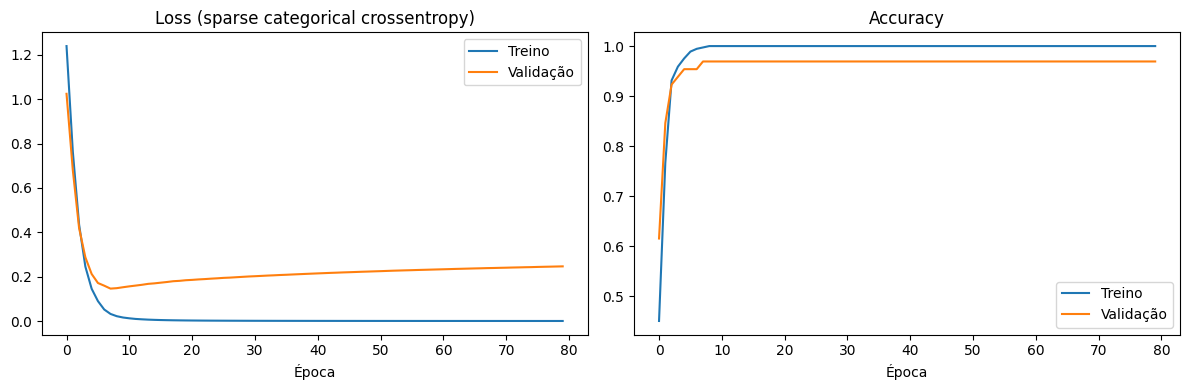

In [8]:
# =========================================================
# CURVAS DE TREINAMENTO
# =========================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Treino")
axes[0].plot(history.history["val_loss"], label="Validação")
axes[0].set_title("Loss (sparse categorical crossentropy)")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Treino")
axes[1].plot(history.history["val_accuracy"], label="Validação")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Época")
axes[1].legend()

plt.tight_layout()
plt.savefig("mlp_softmax_curvas_treinamento.png", dpi=150, bbox_inches="tight")
plt.show()
